# JobShield
## 01 — Exploratory Data Analysis

**Project:** Fake Job Posting Detection Using Deep Neural Networks

**Dataset:** Employment Scam Aegean Dataset (EMSCAD)

### Objectives
1. Understand the dataset structure.
2. Identify missing and duplicate records.
3. Analyse the distribution of legitimate and fraudulent postings.
4. Explore numerical and categorical features.
5. Examine important textual features.
6. Identify preprocessing requirements.

**Target variable:** fraudulent

- 0 = Legitimate
- 1 = Fraudulent

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110

print("Libraries imported successfully.")

Libraries imported successfully.


Loading Dataset

In [2]:
def find_dataset():
    current = Path.cwd()

    search_folders = [current] + list(current.parents)

    for folder in search_folders:
        candidate = folder / "data" / "fake_job_postings.csv"

        if candidate.is_file():
            return candidate

    raise FileNotFoundError(
        "Dataset not found. Run Jupyter from the "
        "FINAL PROJECT folder or its notebooks folder."
    )


dataset_path = find_dataset()

df = pd.read_csv(dataset_path)

required_columns = {"job_id", "fraudulent"}

if not required_columns.issubset(df.columns):
    raise ValueError("Required dataset columns are missing.")

print("Dataset loaded successfully.")
print("Path:", dataset_path)
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Path: d:\the_land_of_the_code\college index\ANN-LAB\FINAL PROJECT\data\fake_job_postings.csv
Shape: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [3]:
print("DATASET OVERVIEW")
print("=" * 50)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nCOLUMN NAMES")
for column in df.columns:
    print("-", column)

print("\nDATA TYPES")
display(
    df.dtypes.rename("Data Type").to_frame()
)

print("\nDATASET SUMMARY")
df.info()

print("\nNUMERICAL SUMMARY")
display(df.describe().T)

print("\nFIRST FIVE RECORDS")
display(df.head())

DATASET OVERVIEW
Number of rows: 17880
Number of columns: 18

COLUMN NAMES
- job_id
- title
- location
- department
- salary_range
- company_profile
- description
- requirements
- benefits
- telecommuting
- has_company_logo
- has_questions
- employment_type
- required_experience
- required_education
- industry
- function
- fraudulent

DATA TYPES


,Data Type
job_id,int64
title,object
location,object
department,object
salary_range,object
company_profile,object
description,object
requirements,object
benefits,object
telecommuting,int64



DATASET SUMMARY
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null 

,count,mean,std,min,25%,50%,75%,max
job_id,17880.0,8940.500000,5161.655742,1.0,4470.75,8940.5,13410.25,17880.0
telecommuting,17880.0,0.042897,0.202631,0.0,0.00,0.0,0.00,1.0
has_company_logo,17880.0,0.795302,0.403492,0.0,1.00,1.0,1.00,1.0
has_questions,17880.0,0.491723,0.499945,0.0,0.00,0.0,1.00,1.0
fraudulent,17880.0,0.048434,0.214688,0.0,0.00,0.0,0.00,1.0



FIRST FIVE RECORDS


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


## 2. Missing Value Analysis

Missing information is common in online job advertisements.

Some postings may not include salary details, benefits,
educational requirements or company profiles.

Our objective is to identify missing values before deciding
how to handle them during preprocessing.

MISSING VALUE SUMMARY


,Missing Values,Percentage
salary_range,15012,83.96
department,11547,64.58
required_education,8105,45.33
benefits,7212,40.34
required_experience,7050,39.43
function,6455,36.10
industry,4903,27.42
employment_type,3471,19.41
company_profile,3308,18.50
requirements,2696,15.08


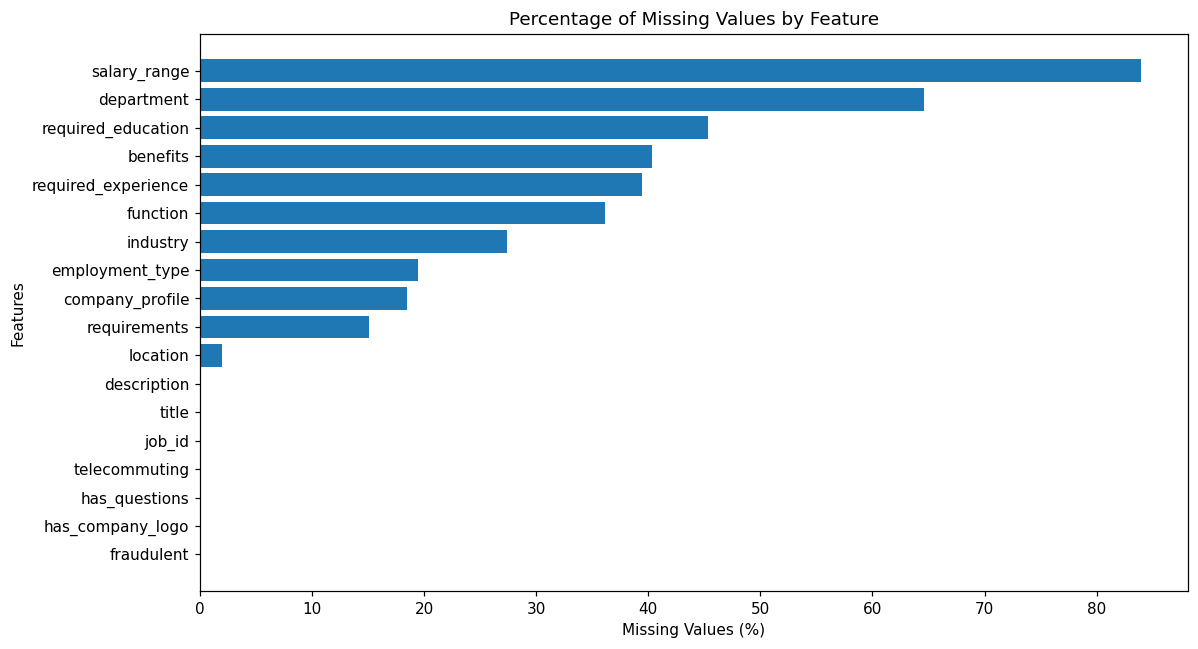

In [4]:
missing = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Percentage": df.isna().mean() * 100
})

missing = missing.sort_values(
    by="Percentage",
    ascending=False
)

print("MISSING VALUE SUMMARY")
display(missing.round(2))

plt.figure(figsize=(11, 6))

plt.barh(
    missing.index,
    missing["Percentage"]
)

plt.gca().invert_yaxis()

plt.title("Percentage of Missing Values by Feature")
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

## 3. Target Variable and Class Imbalance

The target variable is `fraudulent`.

- 0 represents legitimate job postings.
- 1 represents fraudulent job postings.

The dataset is imbalanced because fraudulent advertisements
are much less common than legitimate advertisements.

This makes accuracy alone an insufficient performance metric.

TARGET DISTRIBUTION


,Count,Percentage
Legitimate,17014,95.16
Fraudulent,866,4.84


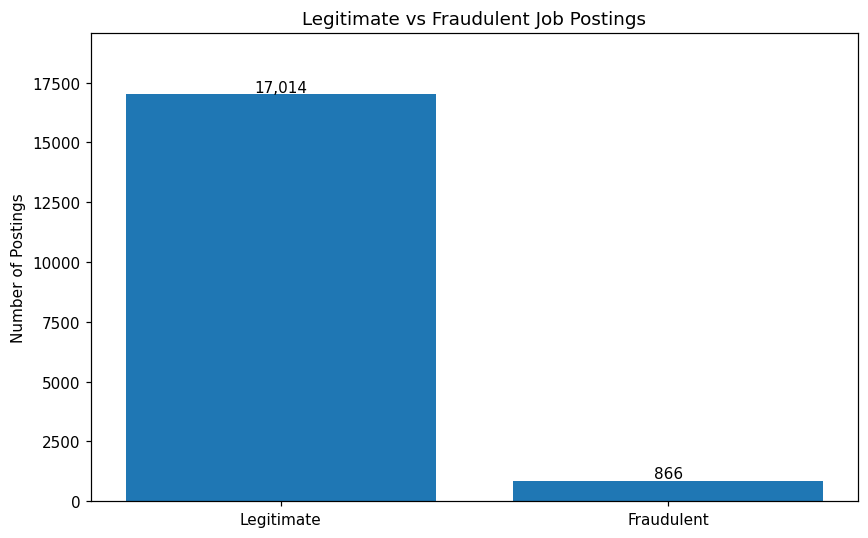

Accuracy of always predicting the majority class: 95.16%


In [5]:
class_counts = df["fraudulent"].value_counts().sort_index()

class_percentages = (
    df["fraudulent"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_summary.index = ["Legitimate", "Fraudulent"]

print("TARGET DISTRIBUTION")
display(class_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    class_summary.index,
    class_summary["Count"]
)

for bar, count in zip(bars, class_summary["Count"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{count:,}",
        ha="center"
    )

ax.set_title("Legitimate vs Fraudulent Job Postings")
ax.set_ylabel("Number of Postings")
ax.set_ylim(0, class_counts.max() * 1.15)

plt.tight_layout()
plt.show()

majority_accuracy = (
    class_counts.max() / len(df)
) * 100

print(
    f"Accuracy of always predicting the majority class: "
    f"{majority_accuracy:.2f}%"
)

## 4. Duplicate Record Analysis

Duplicate advertisements may influence model training and evaluation.

We will examine both:

1. Exact duplicate records.
2. Duplicate records after excluding the unique job identifier.

No records will be removed during this EDA phase.

In [6]:
exact_duplicates = df.duplicated().sum()

feature_columns = [
    column
    for column in df.columns
    if column != "job_id"
]

duplicates_without_id = df.duplicated(
    subset=feature_columns
).sum()

print("Exact duplicate rows:", exact_duplicates)

print(
    "Duplicate rows excluding job_id:",
    duplicates_without_id
)

duplicate_examples = df[
    df.duplicated(
        subset=feature_columns,
        keep=False
    )
]

print("\nExample repeated postings:")

display(
    duplicate_examples[
        ["job_id", "title", "fraudulent"]
    ].head(10)
)

Exact duplicate rows: 0
Duplicate rows excluding job_id: 281

Example repeated postings:


,job_id,title,fraudulent
45,46,Inside Sales Professional-Omaha,0
62,63,English Teacher Abroad,0
83,84,Mail Processing Associate - General Clerk 1,0
85,86,Research Associate,0
102,103,Marketing Administrator,0
106,107,Gatwick Customer Service Apprenticeship 16-18 ...,0
130,131,Customer Service Associate - Call Attendant,0
136,137,Customer Service Associate,0
139,140,Customer Service Associate,0
146,147,Customer Service Associate,0


## 5. Structured Feature Analysis

The dataset includes binary indicators representing whether
a posting supports remote work, contains a company logo or
includes screening questions.

These features may help identify patterns associated with fraud.

We will examine their distributions and their relationship
with the target variable.


FEATURE: telecommuting


,Total_Postings,Fraudulent_Postings,Fraud_Rate
telecommuting,,,
0,17113,802,4.69
1,767,64,8.34


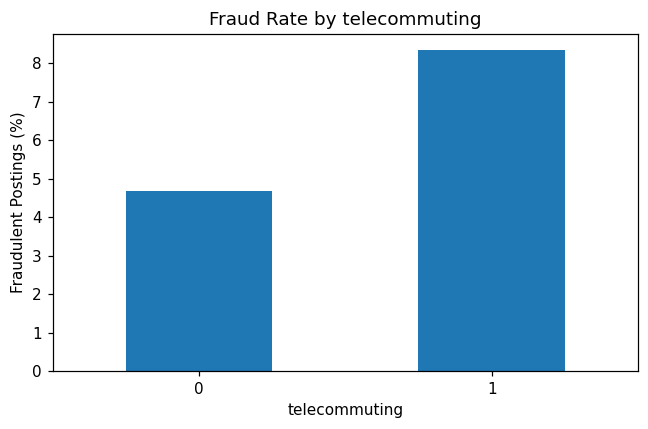


FEATURE: has_company_logo


,Total_Postings,Fraudulent_Postings,Fraud_Rate
has_company_logo,,,
0,3660,583,15.93
1,14220,283,1.99


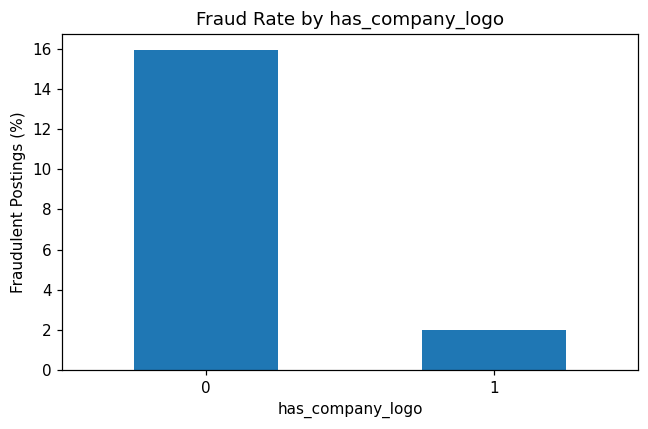


FEATURE: has_questions


,Total_Postings,Fraudulent_Postings,Fraud_Rate
has_questions,,,
0,9088,616,6.78
1,8792,250,2.84


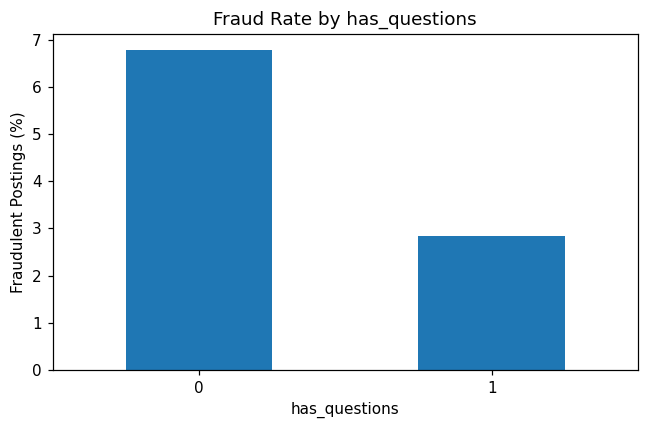

In [7]:
binary_features = [
    "telecommuting",
    "has_company_logo",
    "has_questions"
]

for feature in binary_features:

    print("\nFEATURE:", feature)

    summary = df.groupby(feature).agg(
        Total_Postings=("fraudulent", "size"),
        Fraudulent_Postings=("fraudulent", "sum"),
        Fraud_Rate=("fraudulent", "mean")
    )

    summary["Fraud_Rate"] *= 100

    display(summary.round(2))

    ax = summary["Fraud_Rate"].plot(
        kind="bar",
        figsize=(6, 4),
        rot=0
    )

    ax.set_title(f"Fraud Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Fraudulent Postings (%)")

    plt.tight_layout()
    plt.show()


FEATURE: employment_type


,Count
employment_type,
Full-time,11620
Missing,3471
Contract,1524
Part-time,797
Temporary,241
Other,227



FEATURE: required_experience


,Count
required_experience,
Missing,7050
Mid-Senior level,3809
Entry level,2697
Associate,2297
Not Applicable,1116
Director,389
Internship,381
Executive,141



FEATURE: required_education


,Count
required_education,
Missing,8105
Bachelor's Degree,5145
High School or equivalent,2080
Unspecified,1397
Master's Degree,416
Associate Degree,274
Certification,170
Some College Coursework Completed,102
Professional,74



FEATURE: industry


,Count
industry,
Missing,4903
Information Technology and Services,1734
Computer Software,1376
Internet,1062
Marketing and Advertising,828
Education Management,822
Financial Services,779
Hospital & Health Care,497
Consumer Services,358



FEATURE: function


,Count
function,
Missing,6455
Information Technology,1749
Sales,1468
Engineering,1348
Customer Service,1229
Marketing,830
Administrative,630
Design,340
Health Care Provider,338


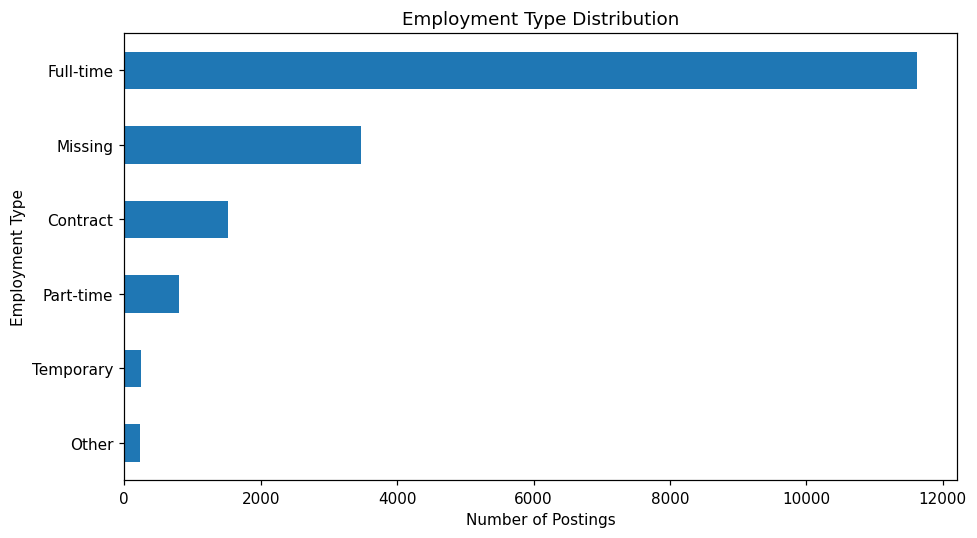

In [8]:
categorical_features = [
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

for feature in categorical_features:

    print("\nFEATURE:", feature)

    counts = (
        df[feature]
        .fillna("Missing")
        .value_counts()
        .head(10)
    )

    display(
        counts.rename("Count").to_frame()
    )

employment_counts = (
    df["employment_type"]
    .fillna("Missing")
    .value_counts()
    .sort_values()
)

employment_counts.plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Employment Type Distribution")
plt.xlabel("Number of Postings")
plt.ylabel("Employment Type")

plt.tight_layout()
plt.show()

## 6. Text Feature Analysis

The dataset contains descriptive text fields that can provide
useful information about job advertisements.

Important fields include:

- Job title
- Company profile
- Job description
- Requirements
- Benefits

We will examine their lengths before selecting a suitable
text feature extraction method.

TF-IDF will be considered during feature engineering.

TEXT LENGTH SUMMARY


,title,company_profile,description,requirements,benefits
count,17880.00,17880.00,17880.00,17880.00,17880.00
mean,28.53,620.90,1218.00,590.13,208.90
std,13.87,567.45,894.83,613.19,337.08
min,3.00,0.00,0.00,0.00,0.00
25%,19.00,138.00,607.00,146.00,0.00
50%,25.00,570.00,1017.00,467.00,45.00
75%,35.00,879.00,1586.00,820.00,294.00
max,142.00,6178.00,14907.00,10864.00,4429.00



MEDIAN TEXT LENGTH BY CLASS


,title,company_profile,description,requirements,benefits
fraudulent,,,,,
0,25.0,588.0,1027.0,476.5,47.0
1,28.0,0.0,844.5,249.0,36.0


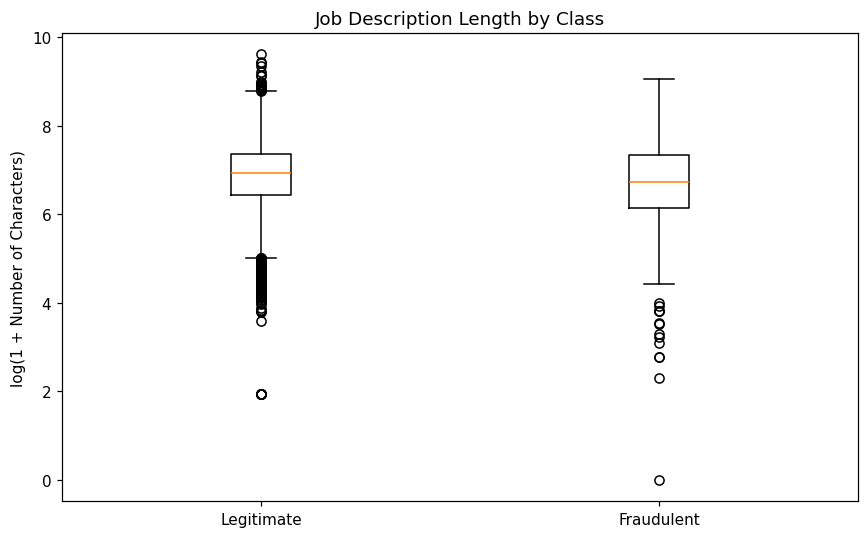

In [9]:
text_features = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

text_lengths = pd.DataFrame(index=df.index)

for feature in text_features:

    text_lengths[feature] = (
        df[feature]
        .fillna("")
        .astype(str)
        .str.len()
    )

print("TEXT LENGTH SUMMARY")

display(
    text_lengths.describe().round(2)
)

text_lengths["fraudulent"] = df["fraudulent"]

print("\nMEDIAN TEXT LENGTH BY CLASS")

display(
    text_lengths.groupby("fraudulent")[
        text_features
    ].median()
)

legitimate_lengths = text_lengths.loc[
    text_lengths["fraudulent"] == 0,
    "description"
]

fraudulent_lengths = text_lengths.loc[
    text_lengths["fraudulent"] == 1,
    "description"
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot([
    np.log1p(legitimate_lengths),
    np.log1p(fraudulent_lengths)
])

ax.set_xticks([1, 2])
ax.set_xticklabels(["Legitimate", "Fraudulent"])

ax.set_title("Job Description Length by Class")
ax.set_ylabel("log(1 + Number of Characters)")

plt.tight_layout()
plt.show()

In [10]:
print("=" * 55)
print("JOBSHIELD — FINAL EDA SUMMARY")
print("=" * 55)

print("Total records:", len(df))
print("Total columns:", df.shape[1])

print(
    "Legitimate:",
    int((df["fraudulent"] == 0).sum())
)

print(
    "Fraudulent:",
    int((df["fraudulent"] == 1).sum())
)

print(
    "Fraud percentage:",
    round(df["fraudulent"].mean() * 100, 2)
)

print(
    "Columns containing missing values:",
    int((df.isna().sum() > 0).sum())
)

print(
    "Duplicate records excluding job_id:",
    int(duplicates_without_id)
)

print("\nSuggested preprocessing tasks:")
print("1. Handle missing values")
print("2. Address duplicate postings")
print("3. Exclude job_id from model features")
print("4. Encode categorical variables")
print("5. Transform text into numerical features")
print("6. Perform stratified train/validation/test splits")
print("7. Fit preprocessing only on training data")
print("8. Handle class imbalance during model training")

JOBSHIELD — FINAL EDA SUMMARY
Total records: 17880
Total columns: 18
Legitimate: 17014
Fraudulent: 866
Fraud percentage: 4.84
Columns containing missing values: 12
Duplicate records excluding job_id: 281

Suggested preprocessing tasks:
1. Handle missing values
2. Address duplicate postings
3. Exclude job_id from model features
4. Encode categorical variables
5. Transform text into numerical features
6. Perform stratified train/validation/test splits
7. Fit preprocessing only on training data
8. Handle class imbalance during model training


## 7. EDA Conclusion

The exploratory analysis provides the following observations:

1. The dataset contains both textual and structured job information.
2. The target variable represents a binary classification problem.
3. The dataset has a substantial class imbalance.
4. Several features contain missing information.
5. Duplicate postings exist when the job identifier is excluded.
6. Text fields require conversion into numerical representations.
7. Model performance must be evaluated using metrics beyond accuracy.

### Implications for Model Development

We will investigate preprocessing, feature engineering and
class weighting.

The dataset will be separated into training, validation and
test sets before fitting any learned preprocessing transformations.

### Next Phase

Phase 2 — Data Preprocessing